# 05 · Water injection

Two-phase water–oil flow on the property model of notebook 04, with the SubsurfiX finite-volume solver:
two-point flux approximation, implicit pressure and explicit saturation, gravity, Brooks–Corey capillary
pressure ([Brooks & Corey 1966](https://doi.org/10.1061/JRCEA4.0000425)) and Peaceman well indices
([Peaceman 1978](https://doi.org/10.2118/6893-PA)). One vertical injector, one deviated producer.

Example assumptions: k = 10^(−1 + 14·φ) mD, doubled in clean cells; kv/kh = 0.1.

## Setup
Set `SX_EXAMPLE_PROJECT` to your KGS project folder (default `kgs_project/` next to this notebook).

In [1]:
import os
from pathlib import Path
import numpy as np, pandas as pd, pyarrow.parquet as pq
import matplotlib.pyplot as plt
%matplotlib inline
# SX_EXAMPLE_PROJECT: KGS project folder (las/, edges/, project.toml), see scripts/fetch_open_data.sh.
# SX_EXAMPLE_OUT: folder for figures and the small model files passed between notebooks.
PROJ = Path(os.environ.get("SX_EXAMPLE_PROJECT", "kgs_project")).resolve()
OUT = Path(os.environ.get("SX_EXAMPLE_OUT", "outputs")).resolve()
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 110})
def save(fig, name):
    fig.savefig(OUT / name, bbox_inches="tight")

## Build the flow model
An 8 × 8 × 6 window around the densest well cluster.

In [2]:
from subsurfix import _native as nat
g, mdl = np.load(OUT / "grid_upscaled.npz"), np.load(OUT / "property_model.npz")
o0, cell, d0 = tuple(g["origin"]), tuple(g["cell"]), tuple(int(v) for v in g["dims"])
i0, j0, nx, ny, nz = 9, 8, 8, 8, 6
sub = lambda a: np.asarray(a).reshape(d0[2], d0[1], d0[0])[:nz, j0:j0 + ny, i0:i0 + nx].ravel()
origin, dims = (o0[0] + i0 * cell[0], o0[1] + j0 * cell[1], 0.0), (nx, ny, nz)
phi = np.clip(sub(mdl["phi"]), 0.03, 0.30)
k_md = 10 ** (-1.0 + 14.0 * phi) * np.where(sub(mdl["clean"]) == 1, 2.0, 1.0)
k = k_md * 9.869e-16
m = nat.FlowModel.from_regular(origin, cell, dims, np.column_stack([k, k, 0.1 * k]), phi)
n = m.n_cells
print(n, "cells; pore volume", round(m.pore_volume().sum() / 1e6, 2), "million m3; median k", np.median(k_md).round(2), "mD")

384 cells; pore volume 77.17 million m3; median k 24.4 mD


## Wells and run
Edit the rates, pressures and fluid properties here.

In [3]:
cid = lambda i, j, kk: i + nx * (j + ny * kk)
inj = {"name": "INJ", "kind": "injector", "rate": 0.02, "cells": [cid(1, 1, kk) for kk in range(nz)], "ref_depth": 0.0}
cx = lambda i: origin[0] + (i + 0.5) * cell[0]
cy = lambda j: origin[1] + (j + 0.5) * cell[1]
path = np.array([[cx(6), cy(6), 0.0], [cx(6), cy(6), 5.0], [cx(4), cy(6), 28.0]])
comp = m.trajectory_completions(path, 0.1, 0.0)
prod = {"name": "PROD", "kind": "producer", "bhp": 1.5e7, "cells": list(comp["cells"]), "wi": list(comp["wi"]), "ref_depth": 0.0}
corey = {"swc": 0.2, "sor": 0.2, "nw": 2.0, "no": 2.0, "mu_w": 5e-4, "mu_o": 2e-3}
phys = {"gravity": 9.81, "rho_w": 1050.0, "rho_o": 800.0, "capillary": "brooks_corey", "pd": 5e3, "lambda": 2.0,
        "c_rock": 5e-10, "c_w": 4e-10, "c_o": 1e-9}
yr = 3.156e7
times = [1 * yr, 3 * yr, 6 * yr, 10 * yr]
p0 = 2e7 + 800 * 9.81 * m.centers()[:, 2]
r = m.run_two_phase([inj, prod], np.full(n, 0.2), p0, times, corey=corey, physics=phys, cfl=0.5, max_dt=2e6)
print("steps", r["n_steps"], "| producer completions", len(comp["cells"]))

steps 1484 | producer completions 8


## Results
Water saturation in the bottom layer, producer rates, and the mass balance check.

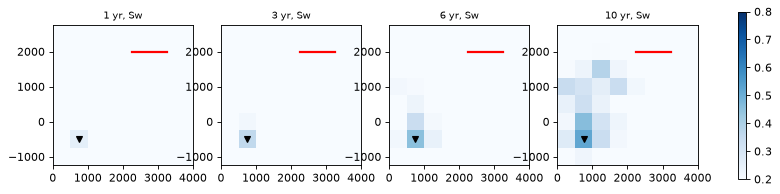

In [4]:
sw = np.array(r["sw"])
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
ext = [origin[0], origin[0] + nx * cell[0], origin[1], origin[1] + ny * cell[1]]
for ax, t, s in zip(axs, times, sw):
    im = ax.imshow(s.reshape(nz, ny, nx)[-1], origin="lower", extent=ext, vmin=0.2, vmax=0.8, cmap="Blues")
    ax.plot(*path[1:, :2].T, "r-", lw=2); ax.plot(cx(1), cy(1), "kv")
    ax.set_title(f"{t / yr:.0f} yr, Sw", fontsize=9)
fig.colorbar(im, ax=axs, shrink=0.8); save(fig, "05_sw_maps.png")

water balance error / net inflow: 1.1e-14
oil balance error / net inflow: 8.1e-14


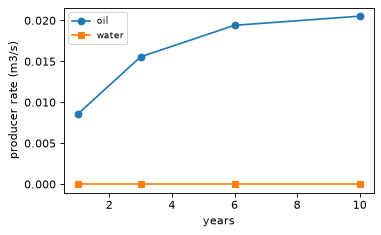

In [5]:
wr, orate = np.array(r["water_rate"]), np.array(r["oil_rate"])
for ph in ("water", "oil"):
    ip, ni = np.array(r[f"{ph}_in_place"]), np.array(r[f"{ph}_net_in"])
    print(f"{ph} balance error / net inflow: {(np.abs(np.diff(ip) - np.diff(ni)) / np.abs(np.diff(ni))).max():.1e}")
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.array(times) / yr, -orate[:, 1], "o-", label="oil"); ax.plot(np.array(times) / yr, -wr[:, 1], "s-", label="water")
ax.set_xlabel("years"); ax.set_ylabel("producer rate (m3/s)"); ax.legend(fontsize=8); save(fig, "05_rates.png")